<a href="https://colab.research.google.com/github/MSGamgee85/MSGamgee85/blob/main/Gestao_Risco_Credito.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Google Colab](https://img.shields.io/badge/Google%20Colab-F9AB00?logo=googlecolab&logoColor=fff)](#) 	[![Python](https://img.shields.io/badge/Python-3776AB?logo=python&logoColor=fff)](#) [![GitHub](https://img.shields.io/badge/GitHub-%23121011.svg?logo=github&logoColor=white)](#)

---

## **Gestão de Risco de Crédito**

---

<u>Risco de crédito</u> é o risco de que ocorra **calote** do tomador de recursos, de tal forma que os juros e o principal não serão pagos ao credor. Instituições financeiras buscam mitigar esse risco através do provisionamento de recursos para cobrir as perdas.

Com base nos conceitos de gestão de risco de crédito apresentados nos livros-texto de Hull e Schroeck (vide referências), o provisionamento e o capital econômico são calculados utilizando-se as <u>métricas</u> de **Perda Esperada (EL)** e **Perda Não Esperada (UL)**, respectivamente.

<br>

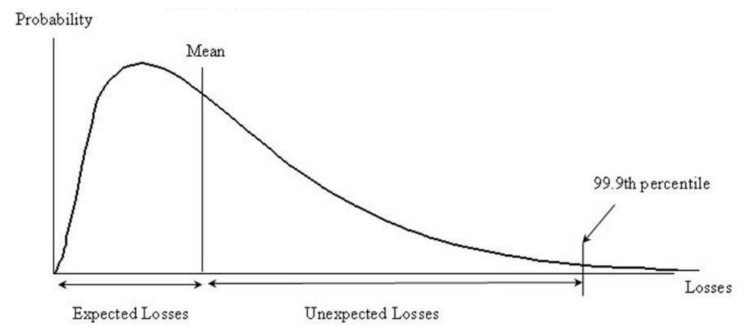

---

<small> **Figura 1.** Distribuição probabilística de perdas para Risco de Crédito. Fonte: JURČA, P. Quantitative methods in risk management. Faculty of Mathematics, Physics and Informatics. Comenius University of Bratislava. Disponível em < http://www.iam.fmph.uniba.sk/institute/jurca/ > Acesso em: 02 maio 2026 </small>

<br>

1. **Provisionamento (Perda Esperada - EL)**
É o valor reservado que representa o <u>custo médio</u> previsível (perda esperada) de uma <u>operação de crédito</u>.

2. **Capital Econômico (Perda Não Esperada - UL)**
É o montante de recurso próprio destinado a absorver perdas que excedem a média, conhecidas como Perdas Não Esperadas (UL); representam a <u>volatilidade do risco</u>.

<br>

Em resumo, o provisionamento é calculado sobre a <u>média das perdas previstas (EL)</u>, enquanto o capital econômico é dimensionado para suportar a <u>variabilidade dessas perdas (UL)</u>, garantindo a **solvência** da instituição em cenários adversos.

---
<small> Nota:
* EL = do inglês "Expected Loss"
* UL = do inglês "Unexpected Loss" </small>

## **Configuração do ambiente**
---

In [98]:
# Bibliotecas utilizadas
import numpy as np                # funções matemáticas e operações com vetores e matrizes
import matplotlib.pyplot as plt   # geração e visualização de gráficos
import pandas as pd               # estruturas tabulares de organização e análise de dados
import warnings                   # gestão de avisos e alertas
warnings.filterwarnings('ignore') # ignora avisos e alertas
from scipy.stats import norm      # distribuição normal da biblioteca scipy
from scipy.optimize import fsolve # encontra raízes de equações não-lineares do tipo f(x) = 0 a partir de uma estimativa

## **1. Portfólio de 2 Ativos Descorrelacionados**

---

<u>Conceitos e Fórmulas</u>:
1. **Perda Esperada (EL)**: É a média da distribuição de perdas. Representa o valor que a instituição espera perder, em média, em suas operações de crédito:

&emsp;&emsp; $\boxed{\sf EL=EAD⋅PD⋅LGD}$ <br>

onde:

* $\sf EAD =$ `exposure at default` = exposição ao calote = valor do crédito/empréstimo concedido ao tomador
* $\sf PD =$ `probability of default` = probabilidade do calote
* $\sf LGD =$ `loss given default` = perda devido ao calote = estimativa da porcentagem do crédito/empréstimo que será perdida no caso de calote
* $\sf RR =$ `recovery rate` = taxa de recuperação = porcentagem do crédito/empréstimo que será recuperada: $\boxed{\sf RR = 1 - LGD}$

&emsp;&emsp; A perda esperada para o portfólio é dada por:

&emsp;&emsp; $\boxed{\sf EL_{P}=\displaystyle \sum_{i=1}^n EL_i}$

2. **Perda Não Esperada (UL)**: Representa a variabilidade (desvio padrão = volatilidade) da perda em torno da média

&emsp;&emsp; Para um ativo:

&emsp;&emsp; $\boxed{\sf UL=EAD \cdot \sqrt{PD \cdot σ^2_{LGD}+LGD^2 \cdot PD(1−PD)}}$

&emsp;&emsp; Para um portfólio com ativos descorrelacionados ($ρ=0$): <br>

&emsp;&emsp; $\boxed{\sf UL_{P} = \sqrt{\displaystyle \sum_{i=1}^n (UL_i)^2}}$

In [26]:
# Parâmetros
ead = 1
sigma_lgd = 0.25
pd_portfolio = np.linspace(0, 0.2, 100) # discretização intervalo PD média portfólio
lgd_valores = [0.25, 0.5, 0.75]

In [27]:
# -- Funções Perda Esperada e Não Esperada --
def el(ead, pd, lgd):
    return ead * pd * lgd # fórmula do EL

def ul(ead, pd, lgd, sigma_lgd):
    return ead * np.sqrt(pd * sigma_lgd**2 + lgd**2 * pd * (1 - pd)) # fórmula do UL

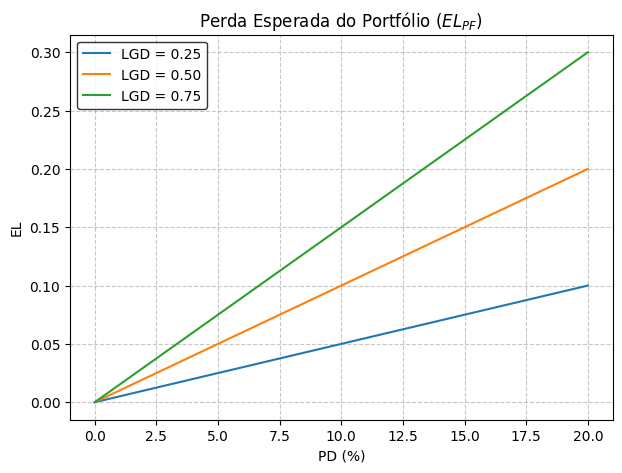

In [43]:
# -- Gráfico EL x PD --
plt.figure(figsize=(7,5))

for lgd in lgd_valores:
    el_pf = 2 * el(ead, pd_portfolio, lgd) # 2 ativos
    plt.plot(pd_portfolio*100, el_pf, label=f'LGD = {lgd:.2f}')

plt.title('Perda Esperada do Portfólio ($EL_{PF}$)')
plt.xlabel('PD (%)')
plt.ylabel('EL')
plt.legend(edgecolor='black')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

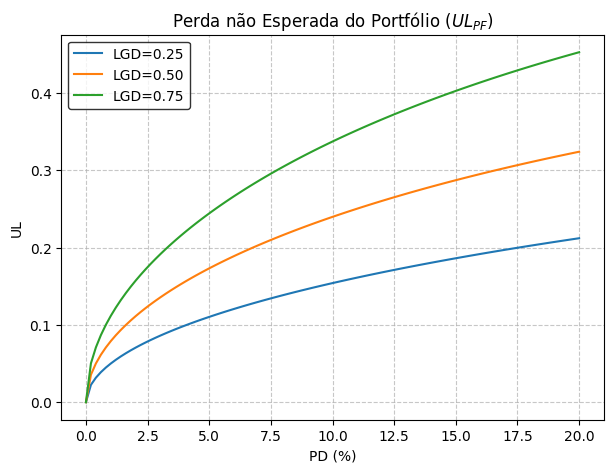

In [45]:
# -- Gráfico UL x PD --
plt.figure(figsize=(7,5))

for lgd in lgd_valores:
    ul_i = ul(ead, pd_portfolio, lgd, sigma_lgd)
    ul_pf = np.sqrt(2 * ul_i**2) # descorrelacionados
    plt.plot(pd_portfolio*100, ul_pf, label=f'LGD={lgd:.2f}')

plt.title('Perda não Esperada do Portfólio ($UL_{PF}$)')
plt.xlabel('PD (%)')
plt.ylabel('UL')
plt.legend(edgecolor='black')
plt.grid(True, linestyle = '--', alpha=0.7)
plt.show()

In [38]:
# Efeito de sigma_LGD na UL
pd_fixo = 0.04                               # 4%
sigma_lgd_intervalo = np.linspace(0, 1, 100) # intervalo da sigma_LGD = [0, 1]

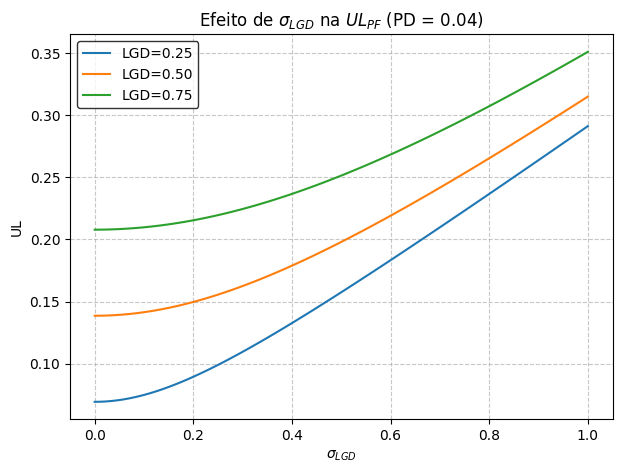

In [46]:
# -- Gráfico UL x sigma_LGD --
plt.figure(figsize=(7, 5))

for lgd in lgd_valores:
    ul_i = ul(ead, pd_fixo, lgd, sigma_lgd_intervalo)
    ul_pf = np.sqrt(2 * ul_i**2)
    plt.plot(sigma_lgd_intervalo, ul_pf, label=f'LGD={lgd:.2f}')

plt.title(f'Efeito de $\sigma_{{LGD}}$ na $UL_{{PF}}$ (PD = {pd_fixo})')
plt.xlabel('$\sigma_{LGD}$')
plt.ylabel('UL')
plt.legend(edgecolor='black')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### **Análise dos Resultados**

---

* O gráfico da $\sf EL$ é linear em relação à $\sf PD$ e à $\sf LGD$. Como os ativos são idênticos, a perda dobra em relação ao ativo individual. O aumento da severidade ($\sf LGD$) inclina a reta da perda esperada

* A $\sf UL$ cresce de forma côncava (formato de raiz quadrada) com a $\sf PD$. Isso ocorre porque a incerteza do default aumenta rapidamente no início, mas o termo $\sf PD \cdot (1 − PD)$ atinge um pico (em $\sf 0.5$, fora do intervalo $\sf [0, 0.2]$).

* Conforme $\sf σ_{LGD}$
aumenta, a incerteza sobre quanto será recuperado em caso de default cresce, elevando diretamente a $\sf UL$. O efeito é mais pronunciado para $\sf LGDs$ menores em termos proporcionais, mas a $\sf UL$ total é sempre maior para $\sf LGDs$ elevados.

## **2. Portfólio Correlacionado**

---

<u>Conceitos e Fórmulas</u>:

* **UL com Correlação (ρ)**: Quando os ativos são correlacionados, o risco do portfólio depende de como os defaults ocorrem simultaneamente:

&emsp; &emsp; $\boxed{\sf UL_{PF}=\sqrt{(UL_1)^2+(UL_2)^2+2⋅ρ_{1,2}⋅UL_1 ⋅ UL_2}}$

&emsp; &emsp; Neste caso, a $\sf LGD$ é determinística e, portanto, $\sf σ
_{LGD}=0$


In [47]:
# Parâmetros
pd1 = 0.02
pd2 = 0.04
lgds = [0, 0.25, 0.5, 0.75, 1.0]
rho = np.linspace(-1, 1, 100) # discretização do intervalo de rho

In [48]:
def ul_det(ead, pd, lgd):
    return ead * lgd * np.sqrt(pd * (1 - pd)) # fórmula UL determinístico (sigma_lgd = 0)

ul1_valores = [ul_det(1, pd1, l) for l in lgds]
ul2_valores = [ul_det(1, pd2, l) for l in lgds]

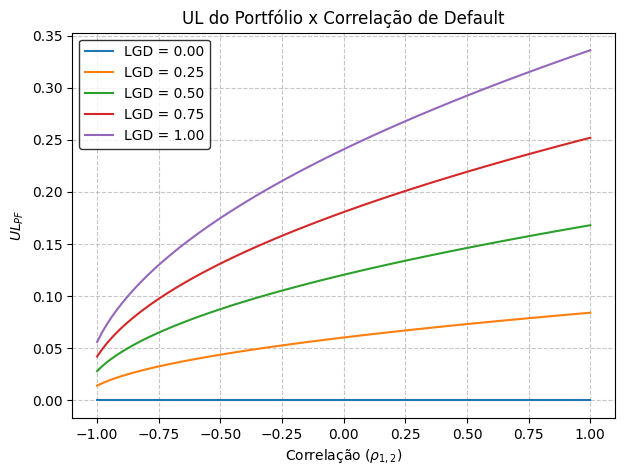

In [53]:
# Gráfico UL x rho
plt.figure(figsize=(7, 5))

for i, lgd in enumerate(lgds):
    ul_pf = np.sqrt(ul1_valores[i]**2 + ul2_valores[i]**2 + 2 * rho * ul1_valores[i] * ul2_valores[i]) # fórmula UL com correlação
    plt.plot(rho, ul_pf, label=f'LGD = {lgd:.2f}')

plt.title('UL do Portfólio x Correlação de Default')
plt.xlabel('Correlação ($\\rho_{1,2}$)')
plt.ylabel('$UL_{PF}$')
plt.legend(edgecolor='black')
plt.grid(True, linestyle = '--', alpha=0.7)
plt.show()

### **Análise dos Resultados**

---

* <u>Efeito da LGD</u>: A $\sf UL$ escala linearmente com a $\sf LGD$ quando esta é determinística. Se $\sf LGD=0$, o risco é zero; se $\sf LGD=1$, o risco é máximo.
* <u>Diversificação</u>: A diversificação é maximizada quando a correlação é mínima ($\sf ρ=−1$). O risco é minimizado em situações de correlação negativa, pois o default de um ativo tende a ser compensado pela sobrevivência do outro.
* <u>Correlação Perfeita</u>: Para $\sf ρ=1$, as perdas são perfeitamente aditivas ($\sf UL_{PF}=UL_1+UL_2$), eliminando o benefício da diversificação.
* <u>Correlação Negativa</u>: Mesmo com $\sf ρ=−1$, a $\sf UL
_{PF}>0$ porque as $\sf ULs$ individuais são diferentes ($\sf PD_1 \neq PD_2$). Para o risco ser zero com $\sf ρ=−1$, as posições teriam que ser idênticas para se anularem perfeitamente.

## **3. Modelo de Merton para Risco de Crédito**

---

<u>Conceitos e Fórmulas</u>:

1. O modelo de Merton trata o patrimônio líquido _ <i>equity</i> _ ($\sf E_t$) como uma **opção de compra** sobre os ativos ($\sf A_t$) da empresa no instante t:

&emsp;&emsp; $\boxed{\sf E_t(r, T, L, A, \sigma_A)=A_t N(d_1)−Le^{−rT}N(d_2)}$

&emsp;&emsp; onde:

- $\sf L=$ montante de juros e principal da dívida a ser paga no tempo T (*Liability* = "passivo");

- $\sf d_1 = \dfrac{ln(\frac{A_t}{L})+(r+\frac{\sigma^2_A}{2})T}{\sigma_A \sqrt{T}}$

- $\sf d_2 = d_1 - \sigma_A \sqrt{T}$

- $\sf σ_E =\frac{σ_A N(d_1)A_t}{E_t}$ = volatilidade instantânea do patrimônio líquido (<i>equity</i>)<br>

- $\sf \sigma_A =$ volatilidade dos ativos (suposta constante)

2. <b>Distância ao Default</b> ($\sf DD$): Mede quantos desvios padrões o valor da empresa está do ponto de insolvência:

&emsp; &emsp; $\boxed{\sf DD=\dfrac{ln(A_t)+(\mu -\frac{\sigma^2_A}{2})T-ln(L)}{\sigma_A \sqrt{T}}}$

&emsp; &emsp; A DD pode ser interpretada como o resultado (valor de saída) do modelo de Merton. Quanto menor o valor de DD, mais provável o risco de calote da empresa.

3. <b>Probabilidade de Defaut ($\sf PD$):</b> é calculada a partir da distribuição normal da distância ao default:

&emsp; &emsp; $\boxed{\sf PD=N(−DD)}$

&emsp; &emsp; onde:

- $\sf N(\cdot)=$ distribuição de probabilidade normal


In [55]:
# Parâmetros
Et = 25000
L = 50000
r = 0.04
T = 1
sigma_e_fixo = 0.4
sigma_a_intervalo = np.arange(0.1, 0.31, 0.01) # intervalo sigma_A

In [57]:
# -- Define as equações do modelo de Merton para risco de crédito --
def merton_eqs(valor_ativo, Et, sigma_e, L, r, T, sigma_a_val):
    At = float(valor_ativo[0])
    d1 = (np.log(At / L) + (r + 0.5 * sigma_a_val**2) * T) / (sigma_a_val * np.sqrt(T))
    d2 = d1 - sigma_a_val * np.sqrt(T)
    eq = sigma_a_val * norm.cdf(d1) * At / Et - sigma_e
    return [eq]

In [62]:
# -- Solução da equação de Merton --
at_sols = [] # cria variável vetor que vai receber as soluções

for sa in sigma_a_intervalo:
    # Estimativa inicial: At = Et + L (necessário para fsolve)
    sol = fsolve(merton_eqs, [Et + L], args=(Et, sigma_e_fixo, L, r, T, sa))
    at_sols.append(sol[0]) # adiciona as soluções encontradas ao vetor

In [64]:
# Calcula DD e PD
at_sols = np.array(at_sols)
d1 = (np.log(at_sols / L) + (r + 0.5 * sigma_a_intervalo**2) * T) / (sigma_a_intervalo * np.sqrt(T))
dd = (np.log(at_sols) + (r - 0.5 * sigma_a_intervalo**2) * T - np.log(L)) / (sigma_a_intervalo * np.sqrt(T))
pd = norm.cdf(-dd)

# Calcula PD e sigma_E
def pd_merton(sigma_e_val, sigma_a_alvo):
    sol = fsolve(merton_eqs, [Et + L], args=(Et, sigma_e_val, L, r, T, sigma_a_alvo))
    At_val = sol[0] # extrai o valor escalar da solução
    dd_val = (np.log(At_val) + (r - 0.5 * sigma_a_alvo**2) * T - np.log(L)) / (sigma_a_alvo * np.sqrt(T))
    return norm.cdf(-dd_val) # calcula o PD

In [110]:
# -- Criação de tabela com os resultados --
df_resultados = pd.DataFrame({
    'σ_A': sigma_a_intervalo,
    'A_t': at_sols,
    'DD': dd,
})

display(df_resultados.head())
print('\n...\n')
display(df_resultados.tail())

,σ_A,A_t,DD
0,0.10,100000.000000,7.281472
1,0.11,90909.091128,5.743518
2,0.12,83333.471487,4.530227
3,0.13,76931.795792,3.557279
4,0.14,71555.395570,2.776064



...



,σ_A,A_t,DD
16,0.26,53819.656944,0.306984
17,0.27,53205.141213,0.243267
18,0.28,52609.055493,0.184519
19,0.29,52028.120425,0.130039
20,0.30,51459.863391,0.079264


In [131]:
# -- Cálculo de PD para valores específicos de sigma_E e sigma_A --
sigma_e_valores = [0.4, 0.3, 0.2]
sigma_a_alvo = 0.3

pd_calculados = [pd_merton(se, sigma_a_alvo) for se in sigma_e_valores] # calcula PD para cada sigma_E

df_resultados = pd.DataFrame({                                          # cria o DataFrame com os resultados formatados
    'σ_E': sigma_e_valores,
    'σ_A': [sigma_a_alvo] * len(sigma_e_valores),
    'PD (%)': pd_calculados
})

df_resultados['PD (%)'] = df_resultados['PD (%)']*100   # formata a coluna PD em % para melhor leitura
display(df_resultados)                                  # exibe a tabela

,σ_E,σ_A,PD (%)
0,0.4,0.3,46.841139
1,0.3,0.3,58.736628
2,0.2,0.3,71.569876


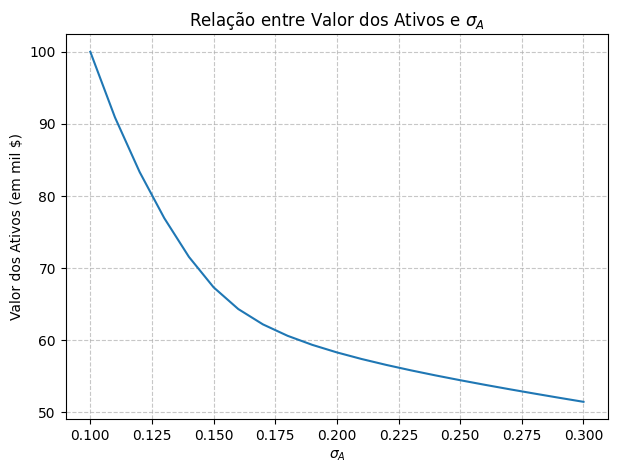

In [97]:
# -- Gráfico 1 = ativos x sigma_a --
plt.figure(figsize=(7, 5))
plt.plot(sigma_a_intervalo, at_sols/1000);
plt.title('Relação entre Valor dos Ativos e $\sigma_A$');
plt.xlabel('$\sigma_A$')
plt.ylabel('Valor dos Ativos (em mil $)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

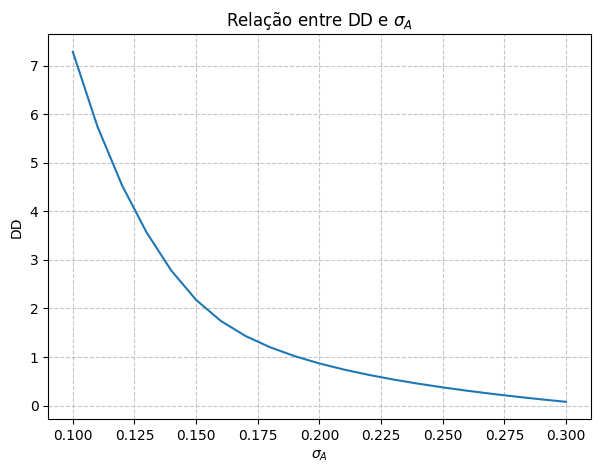

In [92]:
# -- Gráfico 2 = DD x sigma_a --
plt.figure(figsize=(7,5))
plt.plot(sigma_a_intervalo, dd)
plt.title('Relação entre DD e $\sigma_A$')
plt.xlabel('$\sigma_A$');
plt.ylabel('DD')
plt.grid(True, linestyle = '--', alpha=0.7)
plt.show()

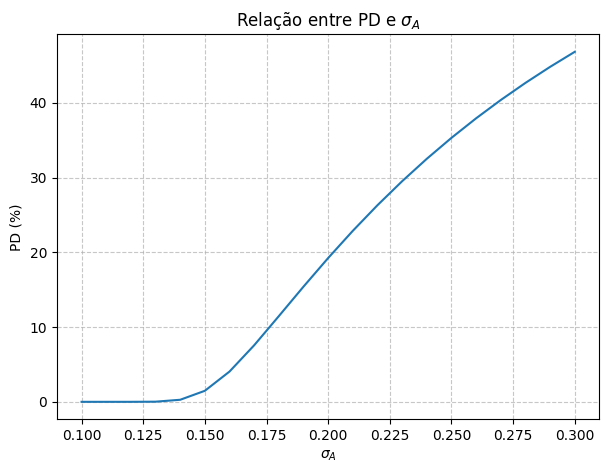

In [91]:
# -- Gráfico 3 = PD x sigma_a --
plt.figure(figsize=(7,5))
plt.plot(sigma_a_intervalo, pd*100);
plt.title('Relação entre PD e $\sigma_A$');
plt.xlabel('$\sigma_A$');
plt.ylabel('PD (%)')
plt.grid(True, linestyle = '--', alpha=0.7)
plt.show()

### **Análise dos Resultados**

---

* <u>Estrutura de Endividamento</u>: À medida que a volatilidade dos ativos ($\sf σ_A$) aumenta, para manter uma volatilidade do equity ($\sf σ_E$
​) constante, o valor implícito dos ativos ($\sf A_t$) tende a ser menor ou a estrutura de capital torna-se mais arriscada. Isso reduz a $\sf DD$ e aumenta a $\sf PD$.
* <u>Variação de</u> $\sf σ_E$: Ao reduzir $\sf σ_E$ de $\sf 0.4$ para $\sf 0.2$ (mantendo $\sf σ_A=0.3$), a $\sf PD$ diminui significativamente. Isso ocorre porque uma menor volatilidade do <i>equity</i>, dado um mesmo risco operacional ($\sf σ_A$), implica que o valor de mercado dos ativos está muito mais acima do nível da dívida ($\sf L$), aumentando a margem de segurança e a distância ao default.

## **Referências**

---

HULL, J. **<i>Risk Management and Financial Institutions**</i>. John Wiley & Sons, 2023.

JURČA, P. **Quantitative methods in risk management**. Faculty of Mathematics, Physics and Informatics. Comenius University of Bratislava. Disponível em < http://www.iam.fmph.uniba.sk/institute/jurca/ > Acesso em: 02 maio 2026.

KHURANA, B. Credit Risk: Expected and Unexpected Losses. **finRGB**, 16 de junho de 2016. Disponível em < https://www.finrgb.com/swatches/credit-risk-expected-unexpected-losses-frm-part-1/ >. Acesso em: 03 maio 2026.

OLIVEIRA, A. **Notas de Aula - Gestão de Riscos**. MBA em Engenharia Financeira. Escola Politécnica da USP. São Paulo, 2026.

SCHROECK, G. **Risk Management and Value Creation in Financial Institutions**. John Wiley & Sons. New York, 2002.